# 1 — Importação das bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Input

from sklearn.metrics import mean_squared_error

np.random.seed(42)
tf.random.set_seed(42)

# 2 — Geração da série temporal
Vamos gerar 10.000 amostras de ruído branco gaussiano e utilizar a equação do enunciado para construir a série temporal.

Precisamos gerar o ruído com duas amostras adicionais para calcular corretamente os atrasos.

In [2]:
# Parâmetro da equação
beta = 0.5

# Quantidade de amostras
N = 10000

# Geração do ruído branco gaussiano
v = np.random.normal(0, 1, N + 2)

# Geração da série temporal
x = v[2:] + beta * v[1:-1] * v[:-2]

# Estatísticas da série
print("Média da série:", np.mean(x))
print("Variância da série:", np.var(x))
print("Variância teórica:", 1.25)

Média da série: -0.009416766877063562
Variância da série: 1.2468549444053953
Variância teórica: 1.25


# 3 — Visualização da série temporal
Antes do treinamento, vamos observar o comportamento da série gerada.

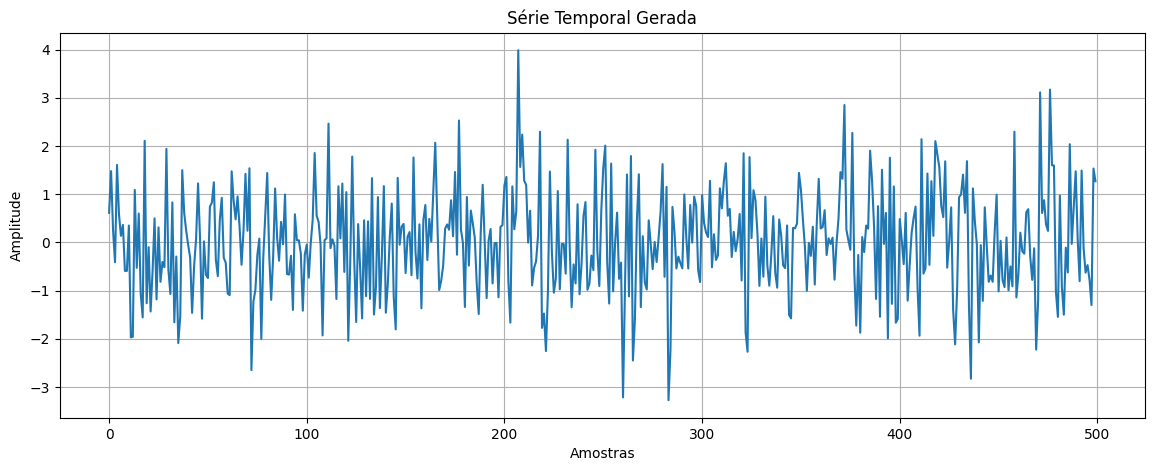

In [4]:
plt.figure(figsize=(14, 5))

plt.plot(x[:500])

plt.title('Série Temporal Gerada')
plt.xlabel('Amostras')
plt.ylabel('Amplitude')

plt.grid()
plt.show()

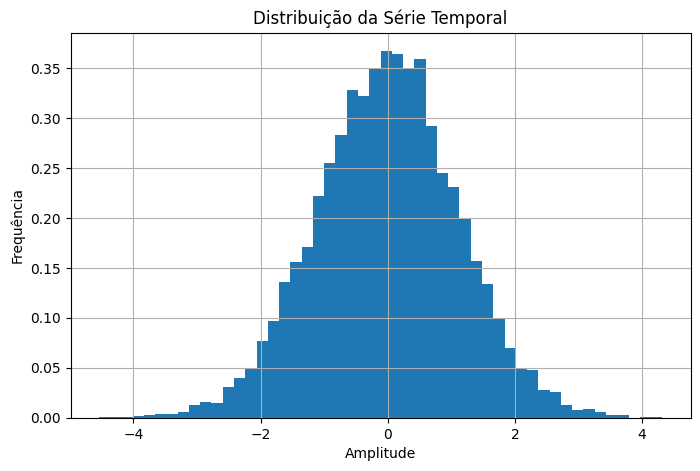

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(x, bins=50, density=True)

plt.title('Distribuição da Série Temporal')
plt.xlabel('Amplitude')
plt.ylabel('Frequência')

plt.grid()
plt.show()

# 4 — Preparação dos dados para predição
Vamos utilizar os três valores anteriores para prever o próximo valor.

Por exemplo:
Entradas	Saída esperada
x(0), x(1), x(2)	x(3)
x(1), x(2), x(3)	x(4)
x(2), x(3), x(4)	x(5)

Assim, a rede aprenderá a relação entre três amostras anteriores e a próxima amostra.

In [6]:
# Quantidade de atrasos
atrasos = 3

X = []
y = []

for i in range(atrasos, len(x)):

    X.append(x[i-atrasos:i])
    y.append(x[i])

X = np.array(X)
y = np.array(y)

print("Formato das entradas:", X.shape)
print("Formato das saídas:", y.shape)

Formato das entradas: (9997, 3)
Formato das saídas: (9997,)


# 5 — Separação dos conjuntos de treinamento e teste
Como estamos trabalhando com séries temporais, não devemos embaralhar os dados.

Vamos utilizar os primeiros 80% para treinamento e os últimos 20% para teste.

In [7]:
# Separação cronológica
limite = int(len(X) * 0.80)

X_treino = X[:limite]
y_treino = y[:limite]

X_teste = X[limite:]
y_teste = y[limite:]

print("Treinamento:", X_treino.shape)
print("Teste:", X_teste.shape)

Treinamento: (7997, 3)
Teste: (2000, 3)


# 6 — Definição da arquitetura NARX
Vamos utilizar três entradas, duas camadas ocultas e um neurônio de saída.

In [8]:
modelo_narx = Sequential([
    Input(shape=(3,)),

    Dense(64, activation='relu'),

    Dense(32, activation='relu'),

    Dense(1, activation='linear')
])

modelo_narx.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='mean_squared_error'
)

modelo_narx.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,369 (9.25 KB)

 Trainable params: 2,369 (9.25 KB)

 Non-trainable params: 0 (0.00 B)

# 7 — Treinamento da rede NARX
Vamos utilizar 100 épocas como limite máximo e reservar os últimos 20% do conjunto de treinamento para validação.

In [9]:
parada_narx = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

historico_narx = modelo_narx.fit(
    X_treino,
    y_treino,
    epochs=100,
    batch_size=64,
    validation_split=0.20,
    shuffle=False,
    callbacks=[parada_narx],
    verbose=1
)

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 1.1337 - val_loss: 1.1900
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.0861 - val_loss: 1.1755
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0782 - val_loss: 1.1714
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0741 - val_loss: 1.1685
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0716 - val_loss: 1.1672
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0699 - val_loss: 1.1663
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0685 - val_loss: 1.1651
Epoch 8/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0673 - val_loss: 1.1650
Epoch 9/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0663 - val_loss: 1.1643
Epoch 10/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0652 - val_loss: 1.1640
Epoch 11/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0644 - val_loss: 1.1640
Epoch 12/100
100/100 ━━━━━━━━━━━━━━━━━━━━

# 8 — Predição utilizando NARX
Agora vamos apresentar o conjunto de teste à rede e obter as previsões de um passo à frente.

In [10]:
# Predições
y_pred_narx = modelo_narx.predict(
    X_teste,
    verbose=0
).flatten()

# Erro de predição
erro_narx = y_teste - y_pred_narx

# MSE
mse_narx = mean_squared_error(
    y_teste,
    y_pred_narx
)

print("MSE da rede NARX:", mse_narx)

MSE da rede NARX: 1.0401652631994833


# 9 — Gráficos da rede NARX
O enunciado solicita três curvas: série temporal, predição e erro de predição.

Vamos apresentar as três no mesmo conjunto de gráficos.

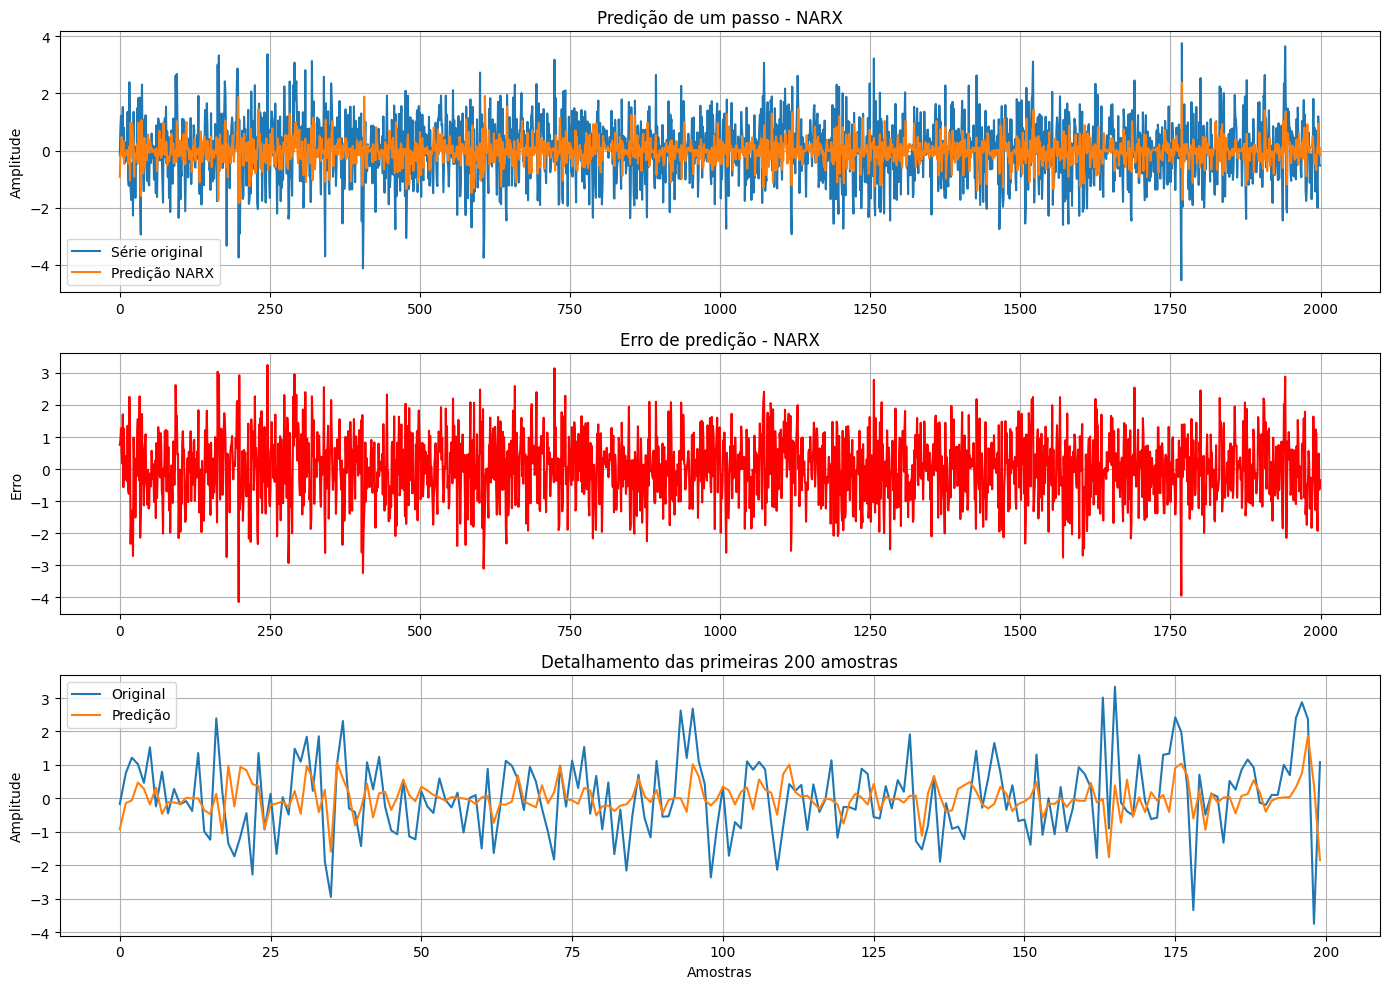

In [11]:
tempo = np.arange(len(y_teste))

fig, ax = plt.subplots(3, 1, figsize=(14, 10))

# Série original e previsão
ax[0].plot(tempo, y_teste, label='Série original')
ax[0].plot(tempo, y_pred_narx, label='Predição NARX')
ax[0].set_title('Predição de um passo - NARX')
ax[0].set_ylabel('Amplitude')
ax[0].legend()
ax[0].grid()

# Erro de predição
ax[1].plot(tempo, erro_narx, color='red')
ax[1].set_title('Erro de predição - NARX')
ax[1].set_ylabel('Erro')
ax[1].grid()

# Comparação em um trecho menor
ax[2].plot(tempo[:200], y_teste[:200], label='Original')
ax[2].plot(tempo[:200], y_pred_narx[:200], label='Predição')
ax[2].set_title('Detalhamento das primeiras 200 amostras')
ax[2].set_xlabel('Amostras')
ax[2].set_ylabel('Amplitude')
ax[2].legend()
ax[2].grid()

plt.tight_layout()
plt.show()

# 10 — Preparação dos dados para LSTM
A LSTM espera receber os dados em três dimensões:

(amostras, passos_temporais, variáveis)

Por isso, precisamos reorganizar os dados que já criamos.

In [19]:
# Redimensionamento para o formato esperado pela LSTM
X_treino_lstm = X_treino.reshape(
    X_treino.shape[0], 3, 1
)

X_teste_lstm = X_teste.reshape(
    X_teste.shape[0], 3, 1
)

print("Formato treinamento:", X_treino_lstm.shape)
print("Formato teste:", X_teste_lstm.shape)

Formato treinamento: (7997, 3, 1)
Formato teste: (2000, 3, 1)


# 11 — Definição da arquitetura LSTM

In [20]:
modelo_lstm = Sequential([
    Input(shape=(3, 1)),

    LSTM(50),

    Dense(25, activation='relu'),

    Dense(1, activation='linear')
])

modelo_lstm.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='mean_squared_error'
)

modelo_lstm.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,701 (45.71 KB)

 Trainable params: 11,701 (45.71 KB)

 Non-trainable params: 0 (0.00 B)

# 12 — Treinamento da LSTM
Vamos utilizar a mesma divisão dos dados e os mesmos critérios de treinamento da NARX, permitindo uma comparação mais justa.

In [21]:
parada_lstm = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

historico_lstm = modelo_lstm.fit(
    X_treino_lstm,
    y_treino,
    epochs=100,
    batch_size=64,
    validation_split=0.20,
    shuffle=False,
    callbacks=[parada_lstm],
    verbose=1
)

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 1.1986 - val_loss: 1.3034
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.1548 - val_loss: 1.2552
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.1174 - val_loss: 1.2015
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.0878 - val_loss: 1.1726
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.0764 - val_loss: 1.1639
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.0711 - val_loss: 1.1603
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.0681 - val_loss: 1.1577
Epoch 8/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.0659 - val_loss: 1.1564
Epoch 9/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 1.0645 - val_loss: 1.1552
Epoch 10/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 1.0633 - val_loss: 1.1538
Epoch 11/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 1.0622 - val_loss: 1.1531
Epoch 12/100
100/100 ━━━━━━━━━━━━━━━━━━━━

# 13 — Predição utilizando LSTM

In [22]:
# Predições
y_pred_lstm = modelo_lstm.predict(
    X_teste_lstm,
    verbose=0
).flatten()

# Erro de predição
erro_lstm = y_teste - y_pred_lstm

# MSE
mse_lstm = mean_squared_error(
    y_teste,
    y_pred_lstm
)

print("MSE da rede LSTM:", mse_lstm)

MSE da rede LSTM: 1.0414326644304277


# 14 — Gráficos da rede LSTM

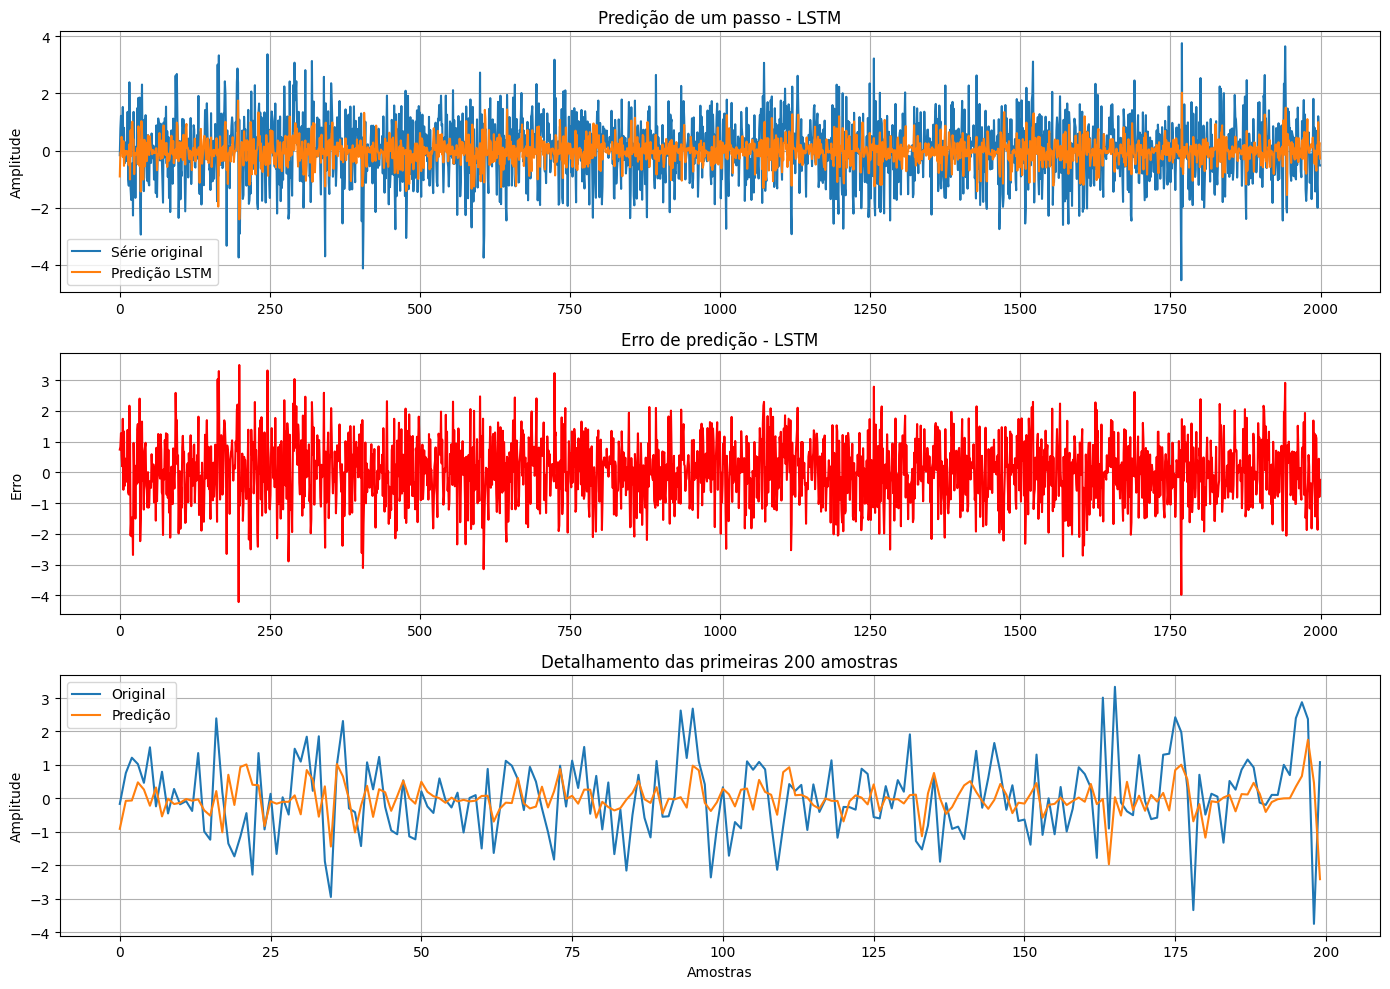

In [23]:
fig, ax = plt.subplots(3, 1, figsize=(14, 10))

# Série original e previsão
ax[0].plot(tempo, y_teste, label='Série original')
ax[0].plot(tempo, y_pred_lstm, label='Predição LSTM')
ax[0].set_title('Predição de um passo - LSTM')
ax[0].set_ylabel('Amplitude')
ax[0].legend()
ax[0].grid()

# Erro de predição
ax[1].plot(tempo, erro_lstm, color='red')
ax[1].set_title('Erro de predição - LSTM')
ax[1].set_ylabel('Erro')
ax[1].grid()

# Comparação em um trecho menor
ax[2].plot(tempo[:200], y_teste[:200], label='Original')
ax[2].plot(tempo[:200], y_pred_lstm[:200], label='Predição')
ax[2].set_title('Detalhamento das primeiras 200 amostras')
ax[2].set_xlabel('Amostras')
ax[2].set_ylabel('Amplitude')
ax[2].legend()
ax[2].grid()

plt.tight_layout()
plt.show()

# 15 — Comparação dos erros

In [24]:
# Cálculo do MSE das duas redes
mse_narx = mean_squared_error(y_teste, y_pred_narx)
mse_lstm = mean_squared_error(y_teste, y_pred_lstm)

# Modelo de referência: previsão igual a zero
mse_referencia = mean_squared_error(
    y_teste,
    np.zeros_like(y_teste)
)

print("MSE NARX:", mse_narx)
print("MSE LSTM:", mse_lstm)
print("MSE referência (previsão zero):", mse_referencia)

MSE NARX: 1.0401652631994833
MSE LSTM: 1.0414326644304277
MSE referência (previsão zero): 1.2262568143042338


# 16 — Gráfico comparativo

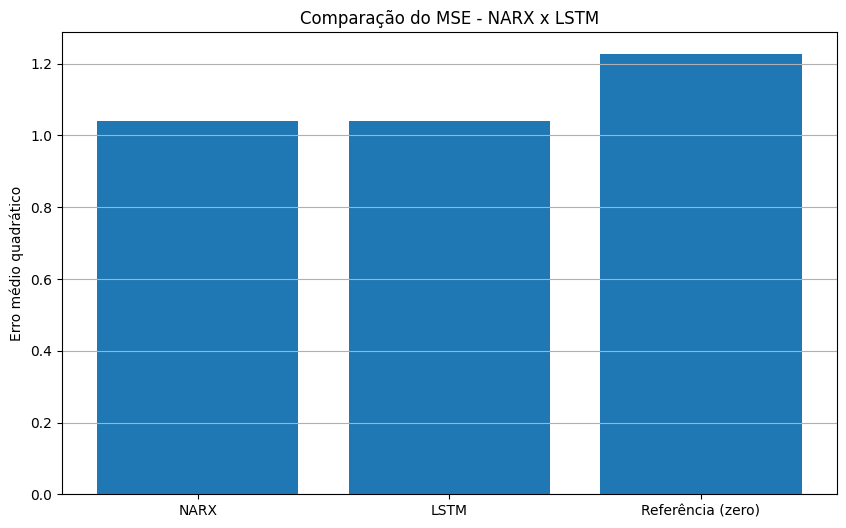

In [25]:
plt.figure(figsize=(10, 6))

modelos = ['NARX', 'LSTM', 'Referência (zero)']
erros = [mse_narx, mse_lstm, mse_referencia]

plt.bar(modelos, erros)

plt.title('Comparação do MSE - NARX x LSTM')
plt.ylabel('Erro médio quadrático')
plt.grid(axis='y')

plt.show()

## Conclusão

Neste experimento foi desenvolvido um sistema de predição de séries temporais utilizando duas arquiteturas de redes neurais: uma rede NARX baseada em Perceptron de Múltiplas Camadas (MLP) e uma rede recorrente LSTM.

A série temporal foi gerada a partir de um ruído branco gaussiano de média zero e variância unitária, considerando o parâmetro β = 0,5, conforme a equação apresentada no enunciado.

Para ambas as arquiteturas, foram utilizadas três amostras anteriores como entradas, com o objetivo de realizar a predição de um passo à frente. Os dados foram divididos cronologicamente em conjuntos de treinamento e teste, preservando a ordem temporal das observações.

A rede NARX utilizou camadas densas com funções de ativação não lineares, enquanto a LSTM empregou mecanismos de memória recorrente para processar a sequência temporal.

O desempenho das arquiteturas foi avaliado por meio dos gráficos da série original, das previsões realizadas e dos respectivos erros de predição. Também foi calculado o erro médio quadrático (MSE), permitindo comparar quantitativamente os resultados.

Por fim, deve-se considerar que a série possui uma componente aleatória proveniente do ruído branco gaussiano, o que limita sua previsibilidade. Dessa forma, a comparação entre NARX e LSTM permite analisar a capacidade de cada arquitetura em aprender as relações não lineares presentes no processo, mesmo diante da incerteza associada ao ruído.